![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 01 | EDA and Baseline

*Project 2 — Machine Learning: From Data to Predictions*

**Team:**
**Dataset:**

---

Steps 1 to 4 of the workflow: frame the problem, look at the data, split once, and score the baseline every model will have to beat.

> **Done when:** your framing is written down, you know what is broken in the data and which columns must go, the split is fixed, and you have a baseline score from cross-validation.

The sections below are a suggested route, not a form to fill in. Add sections, drop them, reorder them — what is graded is the work, not whether you kept the scaffold.

---
## 0. Setup

In [31]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import *

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

---
## 1. Frame the problem

Before any code. In a few sentences:

- **The question:** who or what you predict, for whom, and what they would do with the prediction.
- **The target**, and for classification **the positive class**.
- **The metric**, and why: which mistake costs more?

You wrote a first version on launch day. Update it here as the data teaches you things.

**Question:** a bank calls clients to sell them a term deposit. Before a client gets called I want to predict if they'll subscribe or not. That way the marketing team can call the likely ones first and skip the ones who'll probably say no anyway.

**Target:** `y` (did the client subscribe?), positive class is `yes`.

**Metric:** the model can get it wrong in two ways:

- calling someone who says no (false positive): one wasted call
- skipping someone who would've said yes (false negative): the sale is gone

So missing a yes is worse than a wasted call. I'm guessing there are way fewer yes than no in the data, so accuracy would probably look great even for a model that never finds a single yes. That's why I go with **F1** to compare the models: it only gets high if the model actually finds the yes clients (recall) and is right when it flags someone (precision). And since a missed yes hurts more, I'll keep an eye on recall too.

---
## 2. Load the raw data

Run `python download_data.py <houses|telco|bank|flowers>` from the repo root first. Your files land in `data/raw/`, which is gitignored.

In [32]:
df = load_data()

---
## 3. First look

Shape, column types, a handful of rows. What is one row of this data, and what is the target column?

In [33]:
df.shape

(41188, 21)

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [35]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [36]:
df.sample(5, random_state=RANDOM_STATE)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
32884,57,technician,married,high.school,no,no,yes,cellular,may,mon,371,1,999,1,failure,-1.8,92.893,-46.2,1.299,5099.1,no
3169,55,unknown,married,unknown,unknown,yes,no,telephone,may,thu,285,2,999,0,nonexistent,1.1,93.994,-36.4,4.860,5191.0,no
32206,33,blue-collar,married,basic.9y,no,no,no,cellular,may,fri,52,1,999,1,failure,-1.8,92.893,-46.2,1.313,5099.1,no
9403,36,admin.,married,high.school,no,no,no,telephone,jun,fri,355,4,999,0,nonexistent,1.4,94.465,-41.8,4.967,5228.1,no
14020,27,housemaid,married,high.school,no,yes,no,cellular,jul,fri,189,2,999,0,nonexistent,1.4,93.918,-42.7,4.963,5228.1,no


41,188 rows and 21 columns (20 features + the target `y`). One row = one phone contact with a client in a campaign. `y` is a `yes`/`no` string, so that has to become 1/0 at some point.

No `NaN`s at all, but that doesn't mean nothing's missing: the sample already shows `unknown` in `job`, `education` and `default`, and `pdays` is `999` in every single row of the sample. Will look into that in the data quality part.

The docs split the columns into four groups:

- client data: `age`, `job`, `marital`, `education`, `default`, `housing`, `loan`
- the last contact of this campaign: `contact`, `month`, `day_of_week`, `duration`
- earlier contacts: `campaign`, `pdays`, `previous`, `poutcome`
- the economy at that time: `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed`

11 columns are text (`object`), the rest are numbers. `default`, `housing` and `loan` look like yes/no, but they also have `unknown`, so they're really three categories and not booleans.

The first rows are all May and Monday, but the random sample is all over the place. Turns out the file is sorted by date: the months go May → Nov, Mar → Dec, Mar → Nov, and the docs confirm it's May 2008 to Nov 2010. There's no year column though. The economy columns change over time, so they probably work like a hidden date.

---
## 4. Data quality

Missing values (including ones in disguise, such as `"unknown"`, blanks or `999`), duplicates, numbers stored as text, dates stored as strings. Write down what you find and what you will do about it.

In [37]:
df.isna().sum().sum()

np.int64(0)

In [38]:
unknown = (df == "unknown").sum()
unknown = unknown[unknown > 0]
pd.DataFrame({"count": unknown, "%": (unknown / len(df) * 100).round(1)})

,count,%
job,330,0.8
marital,80,0.2
education,1731,4.2
default,8597,20.9
housing,990,2.4
loan,990,2.4


No real `NaN`s, but six text columns use `unknown` for missing values (the docs say so too). Most of them are pretty small, only `default` has a lot (~21%). `housing` and `loan` both have exactly 990 unknowns, so probably it's the same rows:

In [39]:
(df[["housing", "loan"]] == "unknown").value_counts()

housing  loan 
False    False    40198
True     True       990
Name: count, dtype: int64

Yep, if `housing` is unknown then `loan` is unknown too.

I'll keep `unknown` as its own category instead of filling it in or throwing the rows away. Not knowing something about a client might actually tell us something too (like a client who doesn't want to tell the bank if they have a default). Plus, dropping every row with an unknown would throw away more than a fifth of the data, just because of `default`.

In [40]:
df["default"].value_counts()

default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

`default` has only 3 `yes` in 41k rows, so the column is basically `no` vs `unknown`. Might still be useful because of the unknowns, will check that against the target.

In [41]:
print((df["pdays"] == 999).mean())
pd.crosstab(df["pdays"] == 999, df["poutcome"])

0.9632174419733903


poutcome,failure,nonexistent,success
pdays,,,
False,142,0,1373
True,4110,35563,0


`pdays` is the second hidden missing value: `999` means the client wasn't contacted before. That's 96% of the rows, so the column is almost only `999`. It's also annoying for scaling, because 999 gets treated as "a lot of days" when it really means "never".

And it doesn't fully match the docs either: 4,110 clients with `poutcome` = `failure` (so they *were* contacted before) still have `pdays` = 999. `previous` and `poutcome` agree with each other though, `previous` = 0 is always `nonexistent`. So `previous`/`poutcome` are the better way to tell if someone was contacted before. Plan: swap `pdays` for a yes/no "contacted before" flag or just drop it, since `previous` and `poutcome` already have that info.

In [42]:
df.duplicated().sum()

np.int64(12)

In [43]:
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no


12 rows are exact copies of another row, even `duration` and the economy values are the same. There's no client id, so I can't be 100% sure it's the same client, but the same call length down to the second by pure chance is pretty unlikely. It's only 12 rows, so I'll drop them before the split. Otherwise a copy could end up in both the training and the test set.

In [44]:
df.select_dtypes("object").nunique()

job            12
marital         4
education       8
default         3
housing         3
loan            3
contact         2
month          10
day_of_week     5
poutcome        3
y               2
dtype: int64

All text columns only have a handful of distinct values, so no numbers hiding as text. No real dates either: `month` and `day_of_week` are categories and there's no year. `month` only has 10 values, so no calls in January and February.

### Summary

- `unknown` in `job`, `marital`, `education`, `default`, `housing` and `loan`: keep it as its own category
- `default` has only 3 `yes`: keep it for now and check it against the target
- `pdays` is 999 for "never contacted" (96% of rows) and doesn't match `poutcome`: swap it for a "contacted before" flag or drop it
- 12 exact duplicate rows: drop them before the split
- target `y` is `yes`/`no`: turn it into 1/0

---
## 5. Columns that must go

Identifiers, and **anything that would not be known at the moment you make a prediction**. List them with the reason. A column that looks too good to be true usually is.

No id column, so nothing to drop there. The bigger question is: what do we actually know at the moment of the prediction, which is before the client gets called?

`duration` is the obvious one. It's the length of the call, so you only know it after the call is over, and by then you also know if the client said yes. Let's see how the subscription rate changes with it:

In [45]:
df.groupby(pd.qcut(df["duration"], 5), observed=True)["y"].apply(lambda s: (s == "yes").mean())

duration
(-0.001, 89.0]     0.005246
(89.0, 146.0]      0.032436
(146.0, 222.0]     0.072758
(222.0, 368.0]     0.124556
(368.0, 4918.0]    0.329968
Name: y, dtype: float64

The longer the call, the more clients subscribe: from 0.5% for the shortest calls up to 33% for the longest ones. That's too good to be true, the model would basically just learn "long call = yes". The docs also say it should only be used for benchmarks. So it's out.

In [46]:
df = df.drop(columns="duration")

The economy columns are pretty strong too. For example `nr.employed`:

In [47]:
df.groupby("nr.employed")["y"].apply(lambda s: (s == "yes").mean())

nr.employed
4963.6    0.474016
4991.6    0.521345
5008.7    0.567692
5017.5    0.423903
5023.5    0.511628
5076.2    0.357186
5099.1    0.127959
5176.3    0.100000
5191.0    0.030916
5195.8    0.062992
5228.1    0.053345
Name: y, dtype: float64

Depending on the value, somewhere between 3% and 57% of the clients subscribe. But that's not leakage: these are published economy numbers, so the bank knows them before the call. They're strong because they basically say *when* the call happened (the file is sorted by date), and in some periods way more clients said yes. So they stay.

Everything else stays too:

- client data (`age`, `job`, `marital`, `education`, `default`, `housing`, `loan`): the bank knows this about its clients anyway
- `contact`, `month`, `day_of_week`: known when the call gets planned
- `campaign`: number of calls in this campaign including the current one, so it's known before the call
- `pdays`, `previous`, `poutcome`: about earlier campaigns, so known before

So only `duration` goes.

---
## 6. The target

Its distribution. For classification, the share of each class: this is what makes accuracy honest or misleading. For regression, is it skewed?

First turning `y` into 1/0, `yes` = 1 is the positive class:

In [48]:
df["y"] = (df["y"] == "yes").astype(int)
df["y"].value_counts()

y
0    36548
1     4640
Name: count, dtype: int64

In [49]:
df["y"].value_counts(normalize=True)

y
0    0.887346
1    0.112654
Name: proportion, dtype: float64

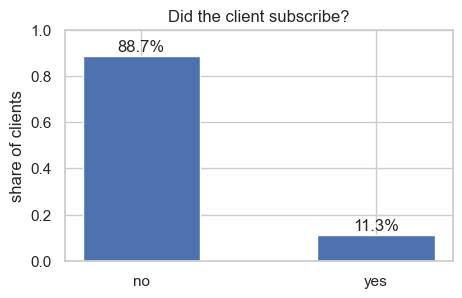

In [50]:
shares = df["y"].value_counts(normalize=True).rename({0: "no", 1: "yes"})

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(shares.index, shares.values, color="#4C72B0", width=0.5)
for i, share in enumerate(shares.values):
    ax.text(i, share + 0.02, f"{share:.1%}", ha="center")
ax.set_ylim(0, 1)
ax.set_ylabel("share of clients")
ax.set_title("Did the client subscribe?")
plt.show()

Only 11.3% of the clients subscribed (4,640 out of 41,188), so yeah, the data is pretty imbalanced. Just saying "no" to everyone would already give 88.7% accuracy without finding a single subscriber. That's exactly why I use F1 and not accuracy.

Things to keep in mind because of that:

- stratify every split, so every fold has around 11% yes
- compare the models with F1 and also look at recall and precision
- try `class_weight="balanced"`
- if I try oversampling (e.g. SMOTE), only on the training data inside each fold

---
## 7. Features against the target

Which features move with the target, and how? Numeric against target, categories against target. Write the takeaway under each chart.

### Categories against the target

Chi-square test and Cramér's V for every text column:

In [51]:
cat_cols = df.select_dtypes("object").columns
cramers_v_table(df, cat_cols).round(3)

,p_value,cramers_v
column,,
poutcome,0.000,0.320
month,0.000,0.274
job,0.000,0.153
contact,0.000,0.145
default,0.000,0.099
education,0.000,0.068
marital,0.000,0.055
day_of_week,0.000,0.025
housing,0.058,0.012


- `poutcome` is the strongest one (0.32), then `month` (0.27)
- `job` and `contact` are weak but clearly there (~0.15), `default` is right at 0.1
- `education`, `marital` and `day_of_week` have tiny p-values, but Cramér's V is almost 0, so the relationship is basically nothing
- `housing` and `loan` have p-values above 0.05, so no relationship with the target at all

Let's look at the share of yes per category for the strongest ones. The dashed line is the overall share (11.3%):

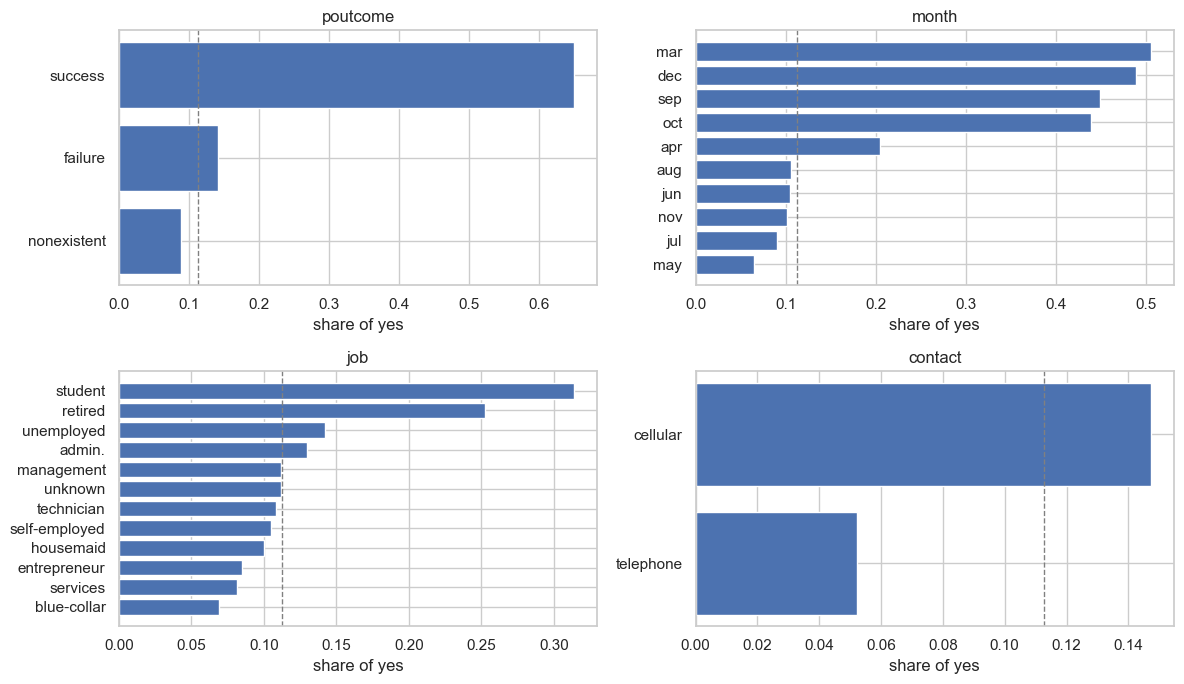

In [52]:
plot_rate_by(df, ["poutcome", "month", "job", "contact"])

- `poutcome`: if the last campaign was a success, 65% of them subscribe again. That's the strongest signal in the whole dataset, but it's only 1,373 clients
- `month`: May has by far the most calls (13,769) but only 6% yes. March, September, October and December are at around 45–50%, but they only have a few hundred calls each. Probably it's not really about the month itself, more about the time period and the economy back then (the file is sorted by date)
- `job`: students (31%) and retired people (25%) say yes way more often, blue-collar workers the least (7%)
- `contact`: cellular 14.7% vs. telephone 5.2%

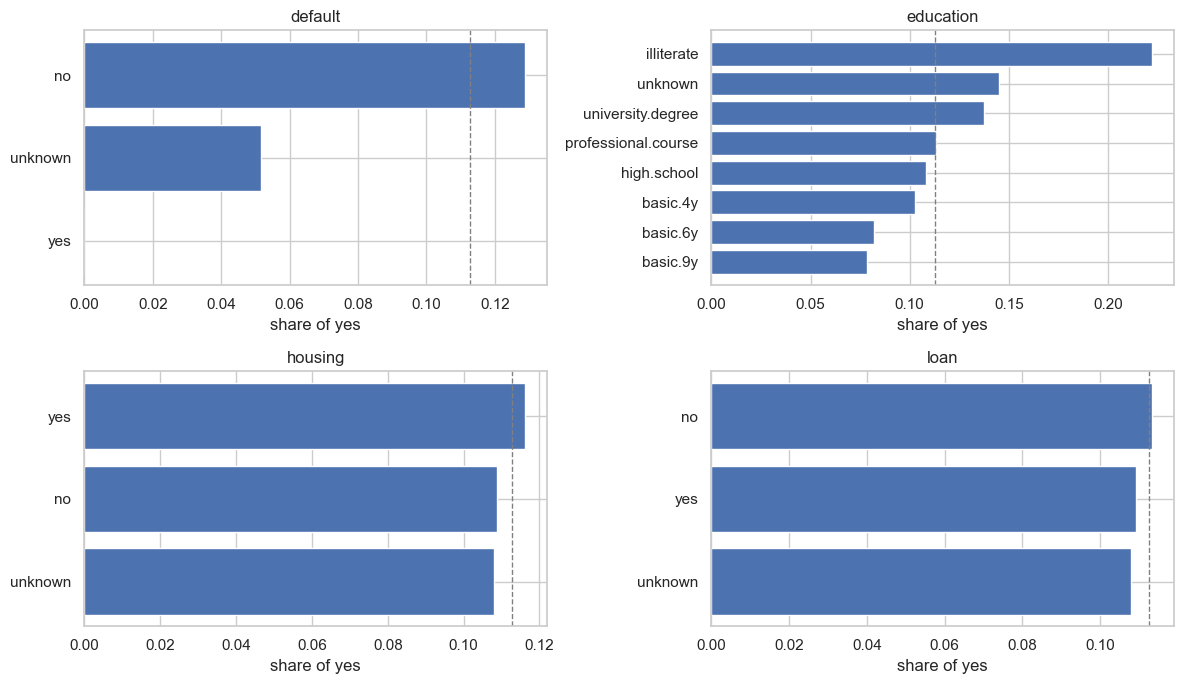

In [53]:
plot_rate_by(df, ["default", "education", "housing", "loan"])

- `default`: clients with `unknown` subscribe less (5.2%) than clients with `no` (12.9%). So the unknowns actually do carry information, nice, since I decided to keep them as a category
- `education`: small differences, `illiterate` looks high but that's only 18 people
- `housing` and `loan`: all bars are pretty much at the overall share, which matches the chi-square test. Candidates to drop. Later I'll compare the cross-validated F1 with and without them and drop them if nothing changes

### Numbers against the target

Spearman correlation of every numeric column with `y`:

In [54]:
num = df.select_dtypes("number")
num.corrwith(num["y"], method="spearman").drop("y").sort_values()

pdays            -0.324942
nr.employed      -0.283957
euribor3m        -0.266822
emp.var.rate     -0.247480
cons.price.idx   -0.122187
campaign         -0.063668
age              -0.011861
cons.conf.idx     0.041229
previous          0.200914
dtype: float64

`pdays` and the economy columns (`nr.employed`, `euribor3m`, `emp.var.rate`) have the strongest (negative) correlation, `previous` the strongest positive one. `age` is almost 0. Box plots for some of them:

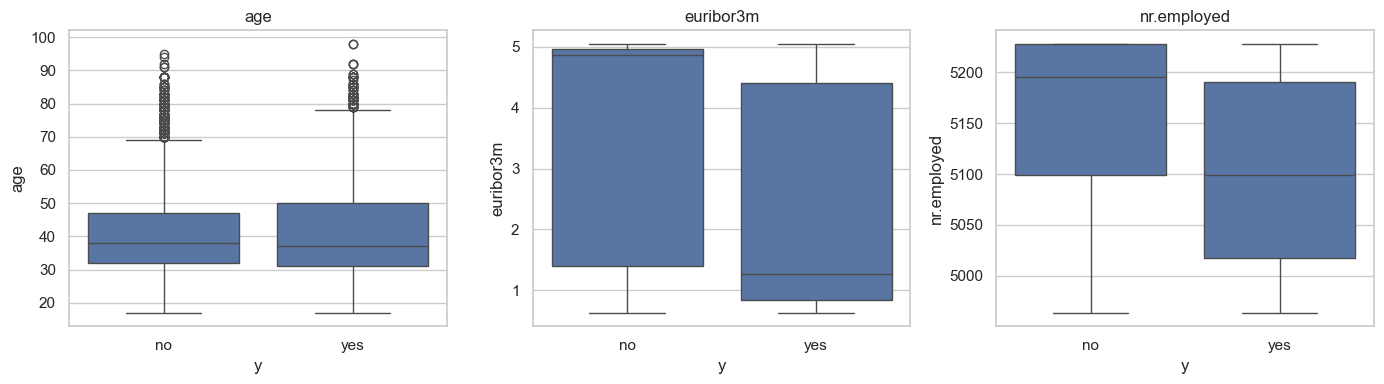

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["age", "euribor3m", "nr.employed"]):
    sns.boxplot(data=df, x="y", y=col, ax=ax)
    ax.set_xticks([0, 1], ["no", "yes"])
    ax.set_title(col)
fig.tight_layout()
plt.show()

- `euribor3m` and `nr.employed`: the yes clients were mostly called when the interest rate and the employment number were low (median euribor 1.3 vs 4.9). That's the "hidden date" again: in the later, worse economic period way more people subscribed
- `age`: the boxes look almost the same, which fits the correlation of ~0. But maybe there's still a pattern that just isn't a straight line. Let's check it in age groups:

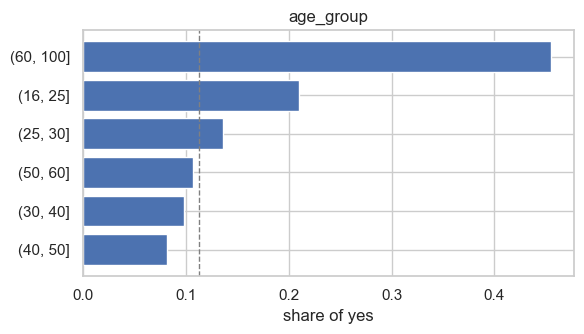

In [56]:
df_age = df.assign(age_group=pd.cut(df["age"], [16, 25, 30, 40, 50, 60, 100]))
plot_rate_by(df_age, ["age_group"], ncols=1)

There it is: clients under 25 (21%) and over 60 (46%) say yes way more often than everyone in between (8–14%). So it's a U-shape. Probably those are mostly the students and retired people from `job`. Age groups might be worth a try as a feature.

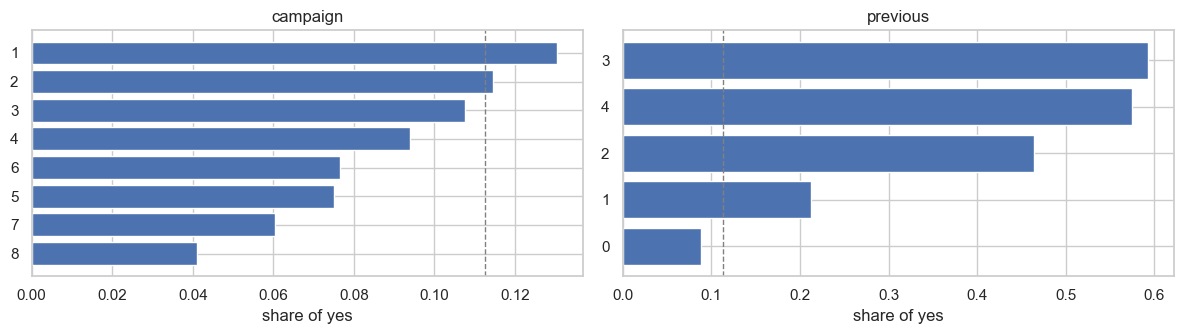

In [57]:
plot_rate_by(df.assign(campaign=df["campaign"].clip(upper=8), previous=df["previous"].clip(upper=4)),
             ["campaign", "previous"])

(`campaign` is cut at 8 and `previous` at 4, so the bars with only a few clients don't mess up the chart.)

- `campaign`: the more often a client got called in this campaign, the less likely they say yes: 13% after 1 call, 4% after 8 or more
- `previous`: the other way around, clients contacted in earlier campaigns say yes more often (9% with 0, 21% with 1, 46% with 2)

### Numbers against each other

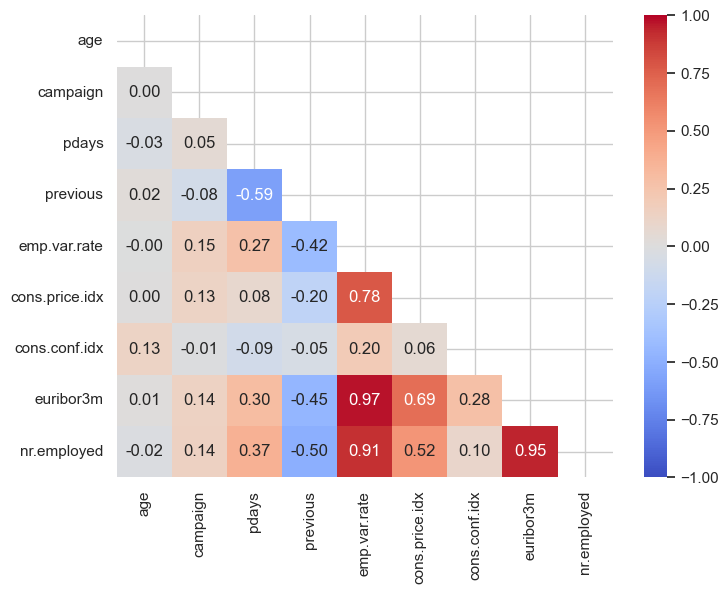

In [58]:
corr = num.drop(columns="y").corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(8, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

`emp.var.rate`, `euribor3m` and `nr.employed` are pretty much the same thing (0.91–0.97), so probably one of them is enough. `pdays` and `previous` are also related (-0.59), which fits what I found about `pdays` earlier.

### Takeaways for the features

- strongest signals: `poutcome`, `previous`, `month`, the economy columns, `contact`, `job`
- `age` matters, just not in a straight line: try age groups
- `campaign`: more calls, fewer yes
- the economy columns repeat each other: try keeping only one
- `housing`, `loan`, `day_of_week`: almost no relationship with the target

---
## 8. Split once

A fixed `random_state`, stratified for classification. From here on, everything happens on the training set; the test set waits until notebook 03.

For the split I load the raw data again and only apply the fixes that don't learn anything from the data: drop the 12 duplicates, drop `duration` and turn `y` into 1/0. The duplicates have to go first, because without `duration` 1,784 rows would suddenly look like duplicates even though they're different calls.

Both steps are in `src/functions.py`, so the next notebooks get exactly the same rows.

In [59]:
data = clean_data(load_data())
X_train, X_test, y_train, y_test = split_data(data)

print(len(X_train), "training rows,", len(X_test), "test rows")
print(f"share of yes: train {y_train.mean():.1%}, test {y_test.mean():.1%}")

32940 training rows, 8236 test rows
share of yes: train 11.3%, test 11.3%


80% training and 20% test, stratified on `y` with `random_state=42`. Both sets have the same share of yes, so the stratification did its job.

The split is random, so calls from all time periods end up in both sets. And since the economy columns work like a date, the test score shows how well the model does on clients from the same period, not on a future campaign. Need to keep that in mind for the final result.

From here on it's only `X_train` and `y_train`. The test set waits until the very end.

---
## 9. Baseline

A `DummyClassifier` or `DummyRegressor`, scored with the cross-validation you will use for every model. Write the number down: it is what next week's models have to beat.

Three dummy models that don't look at the features at all, scored with the same 5 stratified folds and the same metrics every model gets later:

- always "no": the majority class
- random: guesses yes in about 11% of the cases
- always "yes": basically what the bank does now, just calling everyone

In [60]:
from sklearn.dummy import DummyClassifier

cv = make_cv()
scoring = make_scoring()

baselines = {
    "always no": DummyClassifier(strategy="most_frequent"),
    "random": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "always yes": DummyClassifier(strategy="constant", constant=1),
}
compare_models(baselines, X_train, y_train, cv, scoring)

,F1,F1 std,recall,precision,accuracy
model,,,,,
always no,0.000,0.000,0.000,0.000,0.887
random,0.115,0.006,0.114,0.115,0.802
always yes,0.203,0.000,1.000,0.113,0.113


- always "no" has the best accuracy (88.7%) but an F1 of 0, because it never finds a yes. So again: accuracy is useless here
- random guessing gets an F1 of 0.115
- always "yes" finds every subscriber (recall 1.0), but only 11.3% of the calls actually work. That gives an F1 of **0.203**

So the number to beat is **F1 = 0.203**. A model has to do better than just calling everyone.

---
## 10. Into notebook 02

The columns you keep and how each type will be prepared, the features you want to try, and the models you will compare.

**Columns I keep:** all of them except `duration` (already gone).

- numeric: `age`, `campaign`, `pdays`, `previous`, `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed`
- categorical: `job`, `marital`, `education`, `default`, `housing`, `loan`, `contact`, `month`, `day_of_week`, `poutcome`

**How they get prepared** (all inside the pipeline):

- numeric: `StandardScaler` for the models that need it
- categorical: `OneHotEncoder(handle_unknown="ignore")`, with `unknown` as its own category
- no imputer needed, there are no `NaN`s
- `pdays`: swap it for a yes/no "contacted before" flag or drop it

**Features I want to try:**

- age groups instead of (or next to) raw `age`
- the "contacted before" flag
- only one of the economy columns instead of all three (`emp.var.rate`, `euribor3m`, `nr.employed`)
- with and without `housing` and `loan`

**Models I'll compare** (on the same folds, against F1 = 0.203):

- logistic regression
- decision tree
- random forest
- gradient boosting

Each one also with `class_weight="balanced"`. Then tune the best ones and pick the threshold.

---
## Image option

If you chose the flower photos, sections 3 to 7 become: a grid of example photos per class, the number of photos per class, the range of image sizes, and a few photos that are hard or look mislabelled. Section 8 is a fixed split into training, validation and test sets with `image_dataset_from_directory` and a seed. Section 9 is the majority-class accuracy.